<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Polymarket Prediction Markets](https://github.com/Query-farm/vgi-polymarket)

Live odds, order books, trades and on-chain holders, read-only

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-polymarket/blob/main/notebooks/02_keep_events_markets_and_outcomes_distinct.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-polymarket/blob/main/notebooks/README.md)


## 02 · Finding an event does not enumerate its questions

A text hit, a topic-filtered market, and an outcome token identify different populations. How do we move from discovery to one event's actual questions without treating a bounded page as the whole site? We will inspect topic and recurring-series reference slices, materialize bounded event/market candidates, then follow one explicit event ID into its child markets and aligned outcome structs.

**Recorded public responses:** complete, unmodified Gamma bodies acquired on **15 November 2026 UTC**, with exact request URLs, response timestamps and SHA256 in the companion manifest. The two cases are the first two events in an active `Bitcoin` text-search response. This is a selection for identifier accounting, not representative sampling, a calibrated probability model or a trading recommendation. No wallet or account data are read.

### Run and choose one case

Run the base shared-package install, then Run All. The locked local `[runner]` environment and Colab use the same independent worker release. A temporary loopback service supplies exact recordings by default; missing requests fail, with no fallback. `DATA_MODE="live"` explicitly forwards only those recorded public-read URLs and may fail when old cursors expire. Initial bootstrap needs network; replay itself does not contact Polymarket.

`EVENT_CHOICE` selects **1** (the annual Bitcoin-price event) or **2** (the November event). It changes the event lookup and child population; the reference and discovery recordings stay fixed. Run the second choice in a separate output directory.

In [1]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.49":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.49"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.49":
    raise RuntimeError("Install shared tools 0.3.49, restart, and Run All.")

In [2]:
EVENT_CHOICE = 1  # Experiment: 2
DATA_MODE = "replay"  # Explicit "live" has no replay fallback

In [3]:
import json
from datetime import UTC, datetime
from pathlib import Path
from urllib.parse import urlsplit

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from vgi_notebooks import prepare
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

NOTEBOOK_DIR = prepare("polymarket")
from recorded_api import RecordedAPI

assert type(EVENT_CHOICE) is int and EVENT_CHOICE in (1, 2)
assert DATA_MODE in {"replay", "live"}
run_utc = datetime.now(UTC).isoformat()
source_label = (
    "Recorded public Gamma responses · 15 Nov 2026 UTC"
    if DATA_MODE == "replay"
    else f"Live public Gamma responses · run {run_utc[:19]} UTC"
)
manifest = json.loads((NOTEBOOK_DIR / "fixtures/discovery/manifest.json").read_text())
source = RecordedAPI(NOTEBOOK_DIR / "fixtures/discovery", DATA_MODE, Path("artifacts/discovery"))
%matplotlib inline
theme()
session = connect(globals())
con = session.connection
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
assert con.execute("SELECT current_setting('TimeZone')").fetchone()[0] == "UTC"

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'polymarket' (TYPE vgi,
 LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-polymarket@v0.1.0 vgi-polymarket');

,Success


### A reference slice is not a complete vocabulary

`tags` names topics; `series` names recurring event families. They answer different questions. The following **20-row slices** retain provider order; neither sorting nor a WHERE clause can make their absence a completeness guarantee. We keep IDs and labels together and inspect recurring-series status rather than infer that every event belongs to a series.

These are real catalog tables. Their backing scans fetch eight HTTP pages at once, and the engine may read ahead before LIMIT cancels the scan. **Twenty retained rows do not mean twenty downloaded rows or one request.** The later audit measures the actual reads instead of assuming a request budget from SQL LIMIT.

In [5]:
%%sql
CREATE TABLE topic_slice AS SELECT * FROM polymarket.main.tags LIMIT 20;
CREATE TABLE series_slice AS SELECT * FROM polymarket.main.series LIMIT 20;
SELECT tag_id,label,slug FROM topic_slice ORDER BY tag_id;


,tag_id,label,slug
0,100257,keith gill,keith-gill
1,100344,House Races,house-races
2,100392,redbull,redbull
3,100601,virgins,virgins
4,100626,Europa League,europa-league
5,101025,Viktoria Plzen,viktoria-plzen
6,101026,FDIC,fdic
7,101457,Jerry After Dark,jerry-after-dark
8,101655,Wildfire,wildfire
9,101867,product marekt fit,product-marekt-fit


In [6]:
%%sql reference_summary <<
SELECT 'Topic labels' AS reference,count(*) AS retained,count(DISTINCT tag_id) AS unique_ids,
 NULL::BIGINT AS active_open,NULL::BIGINT AS daily FROM topic_slice
UNION ALL
SELECT 'Recurring series',count(*),count(DISTINCT series_id),
 count(*) FILTER(WHERE active AND NOT closed),count(*) FILTER(WHERE recurrence='daily') FROM series_slice;


In [7]:
display(reference_summary)
series_examples = con.execute(
    "SELECT title,recurrence,active,closed FROM series_slice ORDER BY series_id LIMIT 6"
).df()
display(series_examples)
assert reference_summary.retained.eq(20).all()
assert (reference_summary.retained == reference_summary.unique_ids).all()
recurring = reference_summary.iloc[1]
prose(
    f"Each slice retains **20 unique IDs**. Of these 20 recurring series, **{int(recurring.active_open)}** are active and not closed, and **{int(recurring.daily)}** say daily. The visible NFL and other family labels are catalog records, not evidence that the chosen one-off price event belongs to a recurring family. Topic labels and recurrence are separate axes; neither small slice enumerates the site."
)

,reference,retained,unique_ids,active_open,daily
0,Topic labels,20,20,<NA>,<NA>
1,Recurring series,20,20,20,11


,title,recurrence,active,closed
0,NFL,daily,True,False
1,Elon Tweets,weekly,True,False
2,RCP Polling Margin,weekly,True,False
3,CFB,daily,True,False
4,NBA,daily,True,False
5,MLB,daily,True,False


Each slice retains **20 unique IDs**. Of these 20 recurring series, **20** are active and not closed, and **11** say daily. The visible NFL and other family labels are catalog records, not evidence that the chosen one-off price event belongs to a recurring family. Topic labels and recurrence are separate axes; neither small slice enumerates the site.

### Search events; filter markets with a supported topic ID

Text search returns **events**. The separate topic scans use the recorded Crypto tag ID `21`, a supported API filter; they return events and markets respectively. We retain eight rows from each source and keep the populations separate. These are provider-selected pages, not SQL-ranked universes.

The two case IDs came from the recorded search. Choosing one is explicit. Do not invent an `event_slug` parameter for `markets()`: the upstream endpoint can silently ignore unknown filters. To enumerate an event's questions, use `event_markets(event_id)` below.

In [8]:
%%sql
CREATE TABLE search_slice AS
SELECT * FROM polymarket.main.search('Bitcoin',events_status=>'active') LIMIT 8;
CREATE TABLE event_slice AS
SELECT * FROM polymarket.main.events(tag_id=>'21',closed=>'false',order_by=>'volume24hr',ascending=>'false') LIMIT 8;
CREATE TABLE market_slice AS
SELECT * FROM polymarket.main.markets(tag_id=>'21',closed=>'false',order_by=>'volume24hr',ascending=>'false') LIMIT 8;
CREATE TABLE case_ids(choice,event_id) AS VALUES (1,'89502'),(2,'1292829');
CREATE TABLE selected AS
SELECT c.choice,s.event_id,s.title FROM case_ids c JOIN search_slice s USING(event_id)
WHERE choice={{EVENT_CHOICE}};
SELECT event_id,title,market_count,volume_24hr FROM search_slice ORDER BY volume_24hr DESC;


,event_id,title,market_count,volume_24hr
0,89502,What price will Bitcoin hit in 2026?,47,1.633570e+06
1,1292829,What price will Bitcoin hit in November?,33,1.523978e+06
2,1346285,What price will Bitcoin hit November 9-15?,27,1.175026e+06
3,1384356,What price will Bitcoin hit on November 14?,16,9.777767e+05
4,1342183,Bitcoin above ___ on November 15?,11,3.446545e+05
5,1350199,Bitcoin above ___ on November 16?,11,1.273525e+05
6,1380671,Bitcoin above ___ on November 20?,11,9.482861e+04
7,1357726,Bitcoin above ___ on November 17?,11,8.225993e+04


In [9]:
%%sql discovery_summary <<
SELECT 'Text-search events' AS population,count(*) AS rows,count(DISTINCT event_id) AS distinct_ids FROM search_slice
UNION ALL SELECT 'Topic events',count(*),count(DISTINCT event_id) FROM event_slice
UNION ALL SELECT 'Topic markets',count(*),count(DISTINCT condition_id) FROM market_slice;


In [10]:
display(discovery_summary)
assert discovery_summary.rows.eq(8).all()
assert (discovery_summary.rows == discovery_summary.distinct_ids).all()
selected = con.execute("SELECT * FROM selected").df()
assert len(selected) == 1
prose(
    f"The three **eight-row** samples use two different key types: event ID and condition ID. Selected case **{EVENT_CHOICE}** has event ID **{selected.iloc[0].event_id}**. Equal sample sizes do not make their rows interchangeable, and native order is not a complete relevance or volume ranking. Follow this event's explicit ID to obtain its child population."
)

,population,rows,distinct_ids
0,Text-search events,8,8
1,Topic events,8,8
2,Topic markets,8,8


The three **eight-row** samples use two different key types: event ID and condition ID. Selected case **1** has event ID **89502**. Equal sample sizes do not make their rows interchangeable, and native order is not a complete relevance or volume ranking. Follow this event's explicit ID to obtain its child population.

### Expand the chosen event, then classify its questions

Both calls below take the **event ID**. `event()` supplies one event record and its declared market count; `event_markets()` reads the same event endpoint's embedded questions. We materialize each once. This is a bounded lookup, not a guessed filter over all markets.

Each child is identified by `condition_id`, and each aligned outcome has a separate `token_id`. Closed questions can remain children of an open event. We partition returned children before counting accepting-order flags; none of those flags proves that a book is available or that an order will execute.

In [11]:
%%sql
CREATE TABLE detail AS SELECT e.* FROM selected s,LATERAL polymarket.main.event(s.event_id) e;
CREATE TABLE children AS SELECT m.* FROM selected s,LATERAL polymarket.main.event_markets(s.event_id) m;
CREATE TABLE child_outcomes AS
SELECT condition_id,o.item.outcome_index AS outcome_index,o.item.outcome AS outcome,o.item.token_id AS token_id
FROM children CROSS JOIN UNNEST(outcomes) o(item);
CREATE TABLE child_partition AS
SELECT CASE WHEN closed THEN 'Closed'
 WHEN NOT closed AND accepting_orders THEN 'Open; accepting orders'
 WHEN NOT closed AND NOT accepting_orders THEN 'Open; not accepting'
 ELSE 'Status unavailable' END AS status,count(*) AS markets
FROM children GROUP BY status;
SELECT event_id,title,market_count,active,closed,volume_24hr FROM detail;


,event_id,title,market_count,active,closed,volume_24hr
0,89502,What price will Bitcoin hit in 2026?,47,True,False,1.633570e+06


In [12]:
%%sql child_summary <<
SELECT d.event_id,d.title,d.market_count AS declared_markets,
 (SELECT count(*) FROM children) AS returned_markets,
 (SELECT count(DISTINCT condition_id) FROM children) AS distinct_conditions,
 (SELECT count(*) FROM child_outcomes) AS outcome_rows,
 (SELECT count(DISTINCT token_id) FROM child_outcomes) AS distinct_tokens,
 (SELECT count(*) FROM market_slice m WHERE EXISTS(SELECT 1 FROM children c WHERE c.condition_id=m.condition_id)) AS child_matches_in_topic_sample
FROM detail d;


,event_id,title,declared_markets,returned_markets,distinct_conditions,outcome_rows,distinct_tokens,child_matches_in_topic_sample
0,89502,What price will Bitcoin hit in 2026?,47,47,47,94,94,5


,status,markets
0,Closed,19
1,Open; accepting orders,28


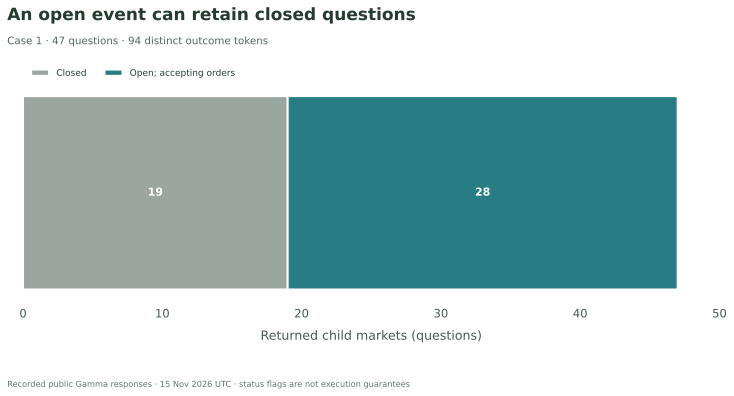

The selected event declares **47** markets; the lookup returns **47 distinct conditions** and **94 distinct outcome tokens**. Only **5** children appear in our separate eight-market topic sample. Absence from that sample is therefore not absence from the event. Closed questions remain part of its child inventory. A condition ID is not an outcome token, and these counts are not a probability or recommendation.

In [13]:
display(child_summary)
partition = con.execute("SELECT * FROM child_partition ORDER BY status").df()
display(partition)
row = child_summary.iloc[0]
fig, ax = plt.subplots(figsize=(11, 5.8))
colors = {
    "Closed": "#9BA6A0",
    "Open; accepting orders": "#287D85",
    "Open; not accepting": "#BD7735",
    "Status unavailable": "#755B8D",
}
left = 0
for item in partition.itertuples():
    ax.barh(
        [0],
        [item.markets],
        left=left,
        color=colors[item.status],
        height=0.45,
        edgecolor="white",
        linewidth=2,
        label=item.status,
    )
    if item.markets >= 2:
        ax.text(
            left + item.markets / 2,
            0,
            str(item.markets),
            ha="center",
            va="center",
            color="white",
            fontweight="bold",
        )
    left += item.markets
ax.set(xlim=(0, max(50, left)), yticks=[], xlabel="Returned child markets (questions)")
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.12), ncol=2, fontsize=9)
finish(
    fig,
    "An open event can retain closed questions",
    f"Case {EVENT_CHOICE} · {row.returned_markets} questions · {row.distinct_tokens} distinct outcome tokens",
    source_label + " · status flags are not execution guarantees",
    name="event-children",
)
prose(
    f"The selected event declares **{row.declared_markets}** markets; the lookup returns **{row.returned_markets} distinct conditions** and **{row.distinct_tokens} distinct outcome tokens**. Only **{row.child_matches_in_topic_sample}** children appear in our separate eight-market topic sample. Absence from that sample is therefore not absence from the event. Closed questions remain part of its child inventory. A condition ID is not an outcome token, and these counts are not a probability or recommendation."
)

### Measure the retrieved population separately from retained rows

The chart compares raw response rows actually served with the SQL slices retained. Each native response is counted once per request; a repeated or read-ahead response is still a real read. The raw bodies remain complete and unmodified. Counts of HTTP reads, response rows, and final SQL records answer different questions.

The two event lookups are excluded from this comparison because they have a different shape: one event envelope with many embedded children. No discovery query is reissued for this chart.

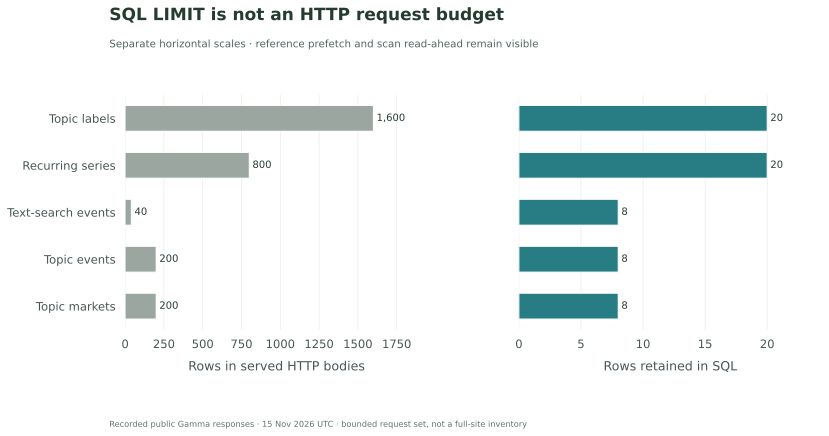

This execution served **40 HTTP reads**, **11,021,951 bytes**. The five SQL slices retain **64 rows** across different populations; the chart counts fetched rows separately. Read-ahead can vary with the execution plan, so no fixed HTTP-count promise is inferred from LIMIT. Every request must match a recorded public read; there is no fallback.

In [14]:
assert all(x["status"] == 200 for x in source.requests), source.requests
entry_by_url = {x["url"]: x for x in manifest["entries"]}
counts = {
    "Topic labels": 0,
    "Recurring series": 0,
    "Text-search events": 0,
    "Topic events": 0,
    "Topic markets": 0,
}
names = {
    "/tags": "Topic labels",
    "/series": "Recurring series",
    "/public-search": "Text-search events",
    "/events/keyset": "Topic events",
    "/markets/keyset": "Topic markets",
}
for request in source.requests:
    path = urlsplit(request["source_url"]).path
    if path in names:
        entry = entry_by_url[request["source_url"]]
        payload = json.loads((Path("artifacts/discovery") / entry["filename"]).read_text())
        rows = payload if isinstance(payload, list) else payload.get("events", payload.get("markets", []))
        counts[names[path]] += len(rows)
received = pd.DataFrame(
    {"population": list(counts), "response_rows": list(counts.values()), "retained": [20, 20, 8, 8, 8]}
)
assert received.response_rows.ge(received.retained).all()
fig, axes = plt.subplots(1, 2, figsize=(11, 6.4), sharey=True)
y = list(range(len(received)))
for ax, key, label, color in [
    (axes[0], "response_rows", "Rows in served HTTP bodies", "#9BA6A0"),
    (axes[1], "retained", "Rows retained in SQL", "#287D85"),
]:
    ax.barh(y, received[key], color=color, height=0.55)
    for i, value in enumerate(received[key]):
        ax.text(value, i, f" {value:,}", va="center", fontsize=10)
    ax.set_xlabel(label)
    ax.set_xlim(0, received[key].max() * 1.22)
    ax.grid(axis="x", visible=True)
axes[0].set_yticks(y, received.population)
axes[0].invert_yaxis()
finish(
    fig,
    "SQL LIMIT is not an HTTP request budget",
    "Separate horizontal scales · reference prefetch and scan read-ahead remain visible",
    source_label + " · bounded request set, not a full-site inventory",
    name="discovery-populations",
)
prose(
    f"This execution served **{len(source.requests)} HTTP reads**, **{sum(x['bytes'] for x in source.requests):,} bytes**. The five SQL slices retain **64 rows** across different populations; the chart counts fetched rows separately. Read-ahead can vary with the execution plan, so no fixed HTTP-count promise is inferred from LIMIT. Every request must match a recorded public read; there is no fallback."
)

In [15]:
%%sql checks <<
SELECT 'selected event is unique' AS invariant,(SELECT count(*) FROM selected)=1 AS passed
UNION ALL SELECT 'lookup matches selected ID',NOT EXISTS(SELECT 1 FROM detail d WHERE d.event_id<>(SELECT event_id FROM selected))
UNION ALL SELECT 'children use selected event ID',NOT EXISTS(SELECT 1 FROM children c WHERE c.event_id<>(SELECT event_id FROM selected))
UNION ALL SELECT 'declared child count reconciles',(SELECT market_count FROM detail)=(SELECT count(*) FROM children)
UNION ALL SELECT 'condition IDs unique',(SELECT count(*)=count(DISTINCT condition_id) FROM children)
UNION ALL SELECT 'tokens unique and present',(SELECT count(*)=count(DISTINCT token_id) AND count(token_id)=count(*) FROM child_outcomes)
UNION ALL SELECT 'partition conserves children',(SELECT sum(markets) FROM child_partition)=(SELECT count(*) FROM children)
UNION ALL SELECT 'outcome indices unique within condition',NOT EXISTS(SELECT 1 FROM child_outcomes GROUP BY condition_id,outcome_index HAVING count(*)<>1)
UNION ALL SELECT 'nonempty child population',(SELECT count(*) FROM children)>0;


In [16]:
display(checks)
assert checks.passed.fillna(False).all()
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
_ = Path("artifacts/discovery-analysis.json").write_text(
    json.dumps(
        {
            "event_choice": EVENT_CHOICE,
            "mode": DATA_MODE,
            "reference": reference_summary.to_dict("records"),
            "discovery": discovery_summary.to_dict("records"),
            "selected": child_summary.to_dict("records"),
            "partition": partition.to_dict("records"),
            "received": received.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": source.requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)

,invariant,passed
0,selected event is unique,True
1,lookup matches selected ID,True
2,children use selected event ID,True
3,declared child count reconciles,True
4,condition IDs unique,True
5,tokens unique and present,True
6,partition conserves children,True
7,outcome indices unique within condition,True
8,nonempty child population,True


### Experiment: change the event, not the discovery evidence

Set `EVENT_CHOICE = 2`, keep replay fixed, and run into a separate output directory. Predict that reference/discovery slices stay identical while the declared/returned child count, status partition and token population change. Check their reconciliations rather than expect the same number of questions. The selected cases have different horizons; do not compare their prices or event volumes as interchangeable exposures.

Restore choice 1 afterwards. This experiment isolates the identifier route against fixed recordings. It says nothing about current books, future outcomes or a complete topic inventory.

In [17]:
session.close()
source.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-polymarket](https://github.com/Query-farm/vgi-polymarket)
